# El perceptrón de Rosenblatt

En 1958 Frank Rosenblatt publicó el **perceptrón**: una neurona artificial con una regla para aprender sus pesos a partir de ejemplos. Fue la primera máquina que aprendía de datos en lugar de ser programada, y llegó a construirse como hardware (el Mark I Perceptron) para reconocer patrones en imágenes. En 1969, Marvin Minsky y Seymour Papert publicaron *Perceptrons*, un análisis matemático de lo que una sola capa de estas neuronas no puede hacer. El ejemplo más citado es XOR. El interés por las redes neuronales cayó durante años, hasta que la retropropagación permitió entrenar redes con capas ocultas.

Esa historia la cuentan con detalle Nils Nilsson en *The Quest for Artificial Intelligence* y Melanie Mitchell en *Artificial Intelligence: A Guide for Thinking Humans* (ver las lecturas del módulo). Este notebook la recorre en código:

1. Preparación
2. Una neurona de umbral
3. La regla de aprendizaje
4. AND y OR
5. Por qué converge: el teorema de Novikoff
6. XOR: el límite de una sola neurona
7. La regla del perceptrón es descenso de gradiente
8. Lo que vino después
9. Resumen y ejercicios

## 1. Preparación

In [1]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Una neurona de umbral

La neurona de `00-fundamentos` calculaba $z = w \cdot x + b$ y lo pasaba por una sigmoide. El perceptrón usa un **umbral**: responde $+1$ si $z > 0$ y $-1$ si no.

$$\hat{y} = \begin{cases} +1 & \text{si } w \cdot x + b > 0 \\ -1 & \text{si no} \end{cases}$$

Usar $\pm 1$ en vez de $1$ y $0$ hace que la regla de aprendizaje quede en una sola línea. La frontera entre las dos respuestas es el conjunto de puntos donde $w \cdot x + b = 0$: en dos dimensiones, una **recta**. El vector $w$ es perpendicular a esa recta y apunta hacia el lado $+1$.

In [2]:
def predecir(X, w, b):
    return torch.where(X @ w + b > 0, 1.0, -1.0)

## 3. La regla de aprendizaje

Se recorren los ejemplos uno por uno. Si un ejemplo está bien clasificado, no se hace nada. Si está mal clasificado, se le suma al peso el ejemplo multiplicado por su etiqueta:

$$w \leftarrow w + y \, x \qquad b \leftarrow b + y$$

Un ejemplo $(x, y)$ está mal clasificado cuando $y \, (w \cdot x + b) \le 0$: el signo de la neurona no coincide con la etiqueta (o el punto cae justo en la frontera). Al número $y \, (w \cdot x + b)$ lo llamamos el **margen funcional** del ejemplo: positivo si acierta, negativo si se equivoca.

Por qué la corrección ayuda: después de la actualización, el margen de ese mismo ejemplo cambia en

$$y \, \big((w + y x) \cdot x + (b + y)\big) - y \, (w \cdot x + b) = y^2 \left(\lVert x \rVert^2 + 1\right) = \lVert x \rVert^2 + 1 > 0$$

Cada error empuja la frontera en la dirección que lo corrige. No hay tasa de aprendizaje ni derivadas.

In [3]:
def entrenar_perceptron(X, y, max_epocas=100):
    w = torch.zeros(X.shape[1])
    b = torch.tensor(0.0)
    errores_por_epoca = []
    for _ in range(max_epocas):
        errores = 0
        for xi, yi in zip(X, y):
            if yi * (xi @ w + b) <= 0:     # mal clasificado
                w = w + yi * xi
                b = b + yi
                errores += 1
        errores_por_epoca.append(errores)
        if errores == 0:                   # una pasada completa sin errores: terminó
            break
    return w, b, errores_por_epoca

## 4. AND y OR

Las compuertas lógicas son el ejemplo clásico. Las entradas son las cuatro combinaciones de 0 y 1, y las etiquetas van en $\pm 1$.

In [4]:
X = torch.tensor([[0.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 0.0],
                  [1.0, 1.0]])

compuertas = {
    "AND": torch.tensor([-1.0, -1.0, -1.0, 1.0]),
    "OR":  torch.tensor([-1.0, 1.0, 1.0, 1.0]),
}

resultados = {}
for nombre, y in compuertas.items():
    w, b, errores = entrenar_perceptron(X, y)
    resultados[nombre] = (w, b)
    print(f"{nombre}: w = {w.tolist()}, b = {b.item()}")
    print(f"     errores por época: {errores}")
    print(f"     predicciones: {predecir(X, w, b).tolist()}   etiquetas: {y.tolist()}\n")

AND: w = [3.0, 2.0], b = -4.0
     errores por época: [2, 3, 3, 2, 2, 3, 2, 1, 0]
     predicciones: [-1.0, -1.0, -1.0, 1.0]   etiquetas: [-1.0, -1.0, -1.0, 1.0]

OR: w = [2.0, 2.0], b = -1.0
     errores por época: [3, 1, 2, 2, 1, 0]
     predicciones: [-1.0, 1.0, 1.0, 1.0]   etiquetas: [-1.0, 1.0, 1.0, 1.0]



Los dos terminan con una época sin errores. Los pesos son enteros porque cada actualización suma un ejemplo de ceros y unos. Para AND, $3x_1 + 2x_2 - 4 > 0$ solo se cumple con las dos entradas en 1: ninguna sola alcanza a superar el $-4$.

Dibujamos la recta $w \cdot x + b = 0$ que encontró en cada caso:

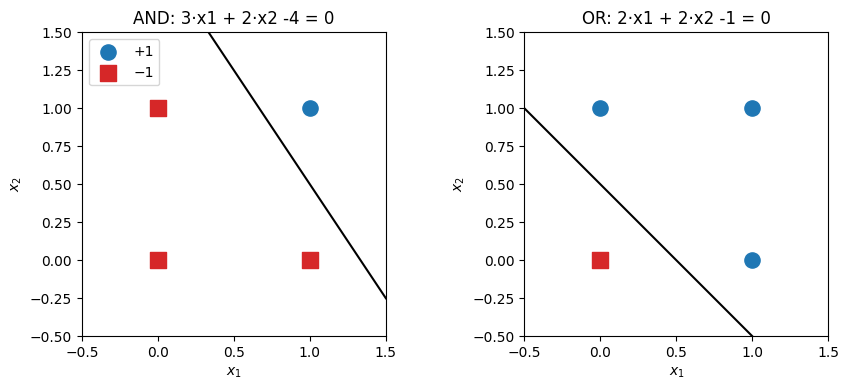

In [5]:
def dibujar_frontera(eje, X, y, w, b, titulo):
    positivos = y > 0
    eje.scatter(X[positivos, 0], X[positivos, 1], s=120, c="tab:blue", label="+1", zorder=3)
    eje.scatter(X[~positivos, 0], X[~positivos, 1], s=120, c="tab:red", marker="s", label="−1", zorder=3)
    x1 = torch.linspace(-0.5, 1.5, 2)
    if w[1] != 0:
        eje.plot(x1, -(w[0] * x1 + b) / w[1], color="black")
    eje.set_xlim(-0.5, 1.5)
    eje.set_ylim(-0.5, 1.5)
    eje.set_xlabel("$x_1$")
    eje.set_ylabel("$x_2$")
    eje.set_title(titulo)
    eje.set_aspect("equal")


fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
for eje, (nombre, y) in zip(ejes, compuertas.items()):
    w, b = resultados[nombre]
    dibujar_frontera(eje, X, y, w, b, f"{nombre}: {w[0]:.0f}·x1 + {w[1]:.0f}·x2 {b:+.0f} = 0")
ejes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5. Por qué converge: el teorema de Novikoff

En 1962 Albert Novikoff demostró que, si existe **alguna** recta (o hiperplano, en más dimensiones) que separa los datos sin errores, el perceptrón la encuentra en un número finito de pasos. Y dio una cota.

Para enunciarlo conviene juntar $w$ y $b$ en un solo vector: $\tilde{w} = (w, b)$ y $\tilde{x} = (x, 1)$, así $w \cdot x + b = \tilde{w} \cdot \tilde{x}$. Sean:

- $u$ un vector **unitario** que separa los datos: $y_i \, (u \cdot \tilde{x}_i) > 0$ para todo $i$.
- $\gamma = \min_i y_i \, (u \cdot \tilde{x}_i)$, el **margen**: la distancia del punto más cercano a la frontera.
- $R = \max_i \lVert \tilde{x}_i \rVert$, el tamaño del dato más grande.

Entonces el número total de actualizaciones $k$ cumple

$$k \le \left(\frac{R}{\gamma}\right)^2$$

**La demostración en dos líneas.** Cada actualización aumenta la componente de $\tilde{w}$ en la dirección de $u$ en al menos $\gamma$, así que tras $k$ actualizaciones $\tilde{w} \cdot u \ge k\gamma$. Y como solo se actualiza cuando $y \, \tilde{w} \cdot \tilde{x} \le 0$, el largo crece poco: $\lVert \tilde{w} + y \tilde{x} \rVert^2 = \lVert \tilde{w} \rVert^2 + 2y\,\tilde{w} \cdot \tilde{x} + \lVert \tilde{x} \rVert^2 \le \lVert \tilde{w} \rVert^2 + R^2$, así que $\lVert \tilde{w} \rVert^2 \le k R^2$. Juntando las dos, $k\gamma \le \tilde{w} \cdot u \le \lVert \tilde{w} \rVert \le \sqrt{k}\,R$, de donde sale la cota.

Lo comprobamos con datos generados a partir de una frontera conocida. Los puntos se reparten a lo largo de la frontera y a una distancia de ella de entre $\gamma$ y $2\gamma$, así que mientras menor es $\gamma$, más fino tiene que ser el ajuste.

In [6]:
def datos_separables(margen, n=200, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    normal = torch.tensor([3.0, 4.0]) / 5          # dirección perpendicular a la frontera
    a_lo_largo = torch.tensor([-4.0, 3.0]) / 5     # dirección de la frontera
    centro = torch.tensor([0.3, -0.2])             # un punto de la frontera, para que b no sea 0

    t = torch.rand(n, generator=generador) * 2 - 1
    y = torch.where(torch.rand(n, generator=generador) < 0.5, -1.0, 1.0)
    distancia = margen * (1 + torch.rand(n, generator=generador))
    X = centro + t[:, None] * a_lo_largo + (y * distancia)[:, None] * normal

    u = torch.cat([normal, -(normal @ centro).reshape(1)])    # la frontera real como vector (w, b)
    u = u / u.norm()
    return X, y, u


def actualizaciones_totales(X, y, max_epocas=100_000):
    w = torch.zeros(X.shape[1])
    b = torch.tensor(0.0)
    total = 0
    for _ in range(max_epocas):
        errores = 0
        for xi, yi in zip(X, y):
            if yi * (xi @ w + b) <= 0:
                w = w + yi * xi
                b = b + yi
                errores += 1
        total += errores
        if errores == 0:
            return total
    raise RuntimeError("no convergió")


filas = []
for margen in [0.2, 0.1, 0.05, 0.02, 0.01]:
    X_s, y_s, u = datos_separables(margen)
    X_aumentado = torch.cat([X_s, torch.ones(len(X_s), 1)], dim=1)
    gamma = (y_s * (X_aumentado @ u)).min().item()
    R = X_aumentado.norm(dim=1).max().item()
    k = actualizaciones_totales(X_s, y_s)
    filas.append((gamma, R, k))
    print(f"margen γ = {gamma:.4f}   R = {R:.3f}   cota (R/γ)² = {(R / gamma) ** 2:8.0f}   actualizaciones = {k:5d}")

margen γ = 0.2018   R = 1.727   cota (R/γ)² =       73   actualizaciones =    12
margen γ = 0.1009   R = 1.697   cota (R/γ)² =      283   actualizaciones =    32
margen γ = 0.0504   R = 1.690   cota (R/γ)² =     1122   actualizaciones =    72


margen γ = 0.0202   R = 1.687   cota (R/γ)² =     6990   actualizaciones =   730


margen γ = 0.0101   R = 1.687   cota (R/γ)² =    27946   actualizaciones =  2251


En todos los casos las actualizaciones quedan bajo la cota, y crecen a medida que el margen se achica. La cota es de peor caso: con estos datos el perceptrón usa entre 6 y 16 veces menos pasos de los que permite.

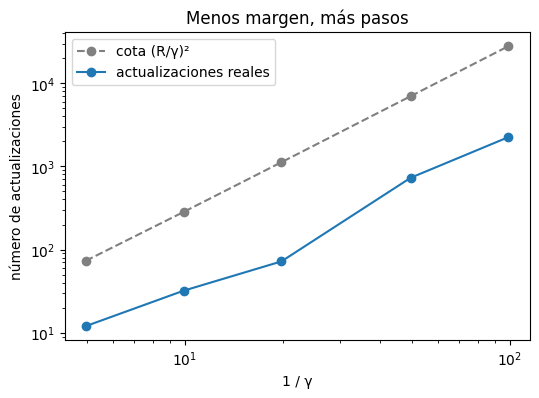

In [7]:
gammas = torch.tensor([g for g, _, _ in filas])
cotas = torch.tensor([(r / g) ** 2 for g, r, _ in filas])
pasos = torch.tensor([k for _, _, k in filas], dtype=torch.float32)

plt.figure(figsize=(6, 4))
plt.loglog(1 / gammas, cotas, "o--", color="gray", label="cota (R/γ)²")
plt.loglog(1 / gammas, pasos, "o-", color="tab:blue", label="actualizaciones reales")
plt.xlabel("1 / γ")
plt.ylabel("número de actualizaciones")
plt.title("Menos margen, más pasos")
plt.legend()
plt.show()

## 6. XOR: el límite de una sola neurona

XOR responde $+1$ cuando las entradas son distintas. Probemos:

In [8]:
y_xor = torch.tensor([-1.0, 1.0, 1.0, -1.0])

w, b, errores = entrenar_perceptron(X, y_xor, max_epocas=10)
print("errores por época:", errores)
print("w final:", w.tolist(), "  b final:", b.item())

errores por época: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
w final: [0.0, 0.0]   b final: 0.0


Nunca hay una época sin errores, y los pesos terminan cada pasada exactamente donde empezaron. En la primera época se equivoca en los cuatro puntos, y las cuatro correcciones se cancelan:

$$\sum_i y_i \, x_i = -(0,0) + (0,1) + (1,0) - (1,1) = (0, 0) \qquad \sum_i y_i = -1 + 1 + 1 - 1 = 0$$

así que la segunda época repite a la primera, y así para siempre. El perceptrón queda dando vueltas en un ciclo.

No es mala suerte con el orden de los datos: **no existe ninguna recta** que separe XOR. Con salidas $+1$ si $w \cdot x + b > 0$, las cuatro condiciones serían:

| Entrada | Etiqueta | Condición |
|---|---|---|
| (0, 0) | −1 | $b \le 0$ |
| (1, 1) | −1 | $w_1 + w_2 + b \le 0$ |
| (1, 0) | +1 | $w_1 + b > 0$ |
| (0, 1) | +1 | $w_2 + b > 0$ |

Sumando las dos últimas: $w_1 + w_2 + 2b > 0$, o sea $w_1 + w_2 + b > -b \ge 0$, que contradice la segunda. El dibujo lo muestra: los dos puntos azules están en una diagonal y los rojos en la otra.

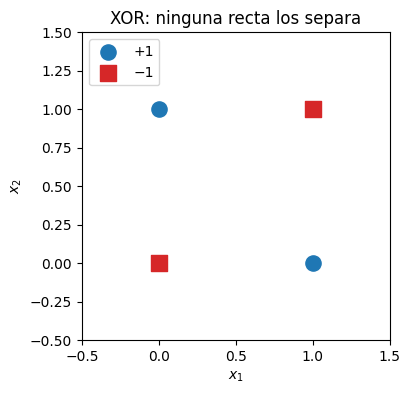

In [9]:
fig, eje = plt.subplots(figsize=(4.5, 4))
dibujar_frontera(eje, X, y_xor, torch.zeros(2), torch.tensor(0.0), "XOR: ninguna recta los separa")
eje.legend(loc="upper left")
plt.show()

Esto es lo que formalizaron Minsky y Papert: una sola capa de neuronas de umbral solo resuelve problemas **linealmente separables**. XOR es el ejemplo más pequeño, pero el libro va mucho más lejos: estudia propiedades de imágenes, como saber si una figura es conexa, y muestra que un perceptrón cuyas unidades miran cada una un trozo limitado de la imagen no puede decidirlas. Para una máquina pensada para reconocer imágenes, era un golpe directo.

## 7. La regla del perceptrón es descenso de gradiente

La regla de Rosenblatt parece un invento aparte, pero es descenso de gradiente estocástico sobre una pérdida concreta, la **pérdida del perceptrón**:

$$L(w, b) = \max\big(0, \; -y\,(w \cdot x + b)\big)$$

Vale 0 si el ejemplo está bien clasificado y crece a medida que el margen es más negativo. Donde el ejemplo está mal clasificado, su gradiente es $\nabla_w L = -y\,x$ y $\partial L / \partial b = -y$, así que un paso de SGD con tasa 1 es exactamente $w \leftarrow w + y\,x$.

Hay un detalle en el borde: en el punto $y\,(w \cdot x + b) = 0$ la función no es derivable. La regla original actualiza también ahí (es lo que la saca de $w = 0$ al empezar), así que escribimos la pérdida con `torch.where` para que en ese caso tome la rama $-y\,(w \cdot x + b)$:

In [10]:
def entrenar_con_sgd(X, y, epocas):
    w = torch.zeros(X.shape[1], requires_grad=True)
    b = torch.zeros((), requires_grad=True)
    optimizador = torch.optim.SGD([w, b], lr=1.0)
    for _ in range(epocas):
        for xi, yi in zip(X, y):
            margen = yi * (xi @ w + b)
            perdida = torch.where(margen <= 0, -margen, 0.0)
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
    return w.detach(), b.detach()


for nombre, y in compuertas.items():
    w_regla, b_regla, errores = entrenar_perceptron(X, y)
    w_sgd, b_sgd = entrenar_con_sgd(X, y, epocas=len(errores))
    iguales = torch.equal(w_regla, w_sgd) and torch.equal(b_regla, b_sgd)
    print(f"{nombre}: regla {w_regla.tolist()}, {b_regla.item()}   SGD {w_sgd.tolist()}, {b_sgd.item()}   ¿iguales? {iguales}")

AND: regla [3.0, 2.0], -4.0   SGD [3.0, 2.0], -4.0   ¿iguales? True
OR: regla [2.0, 2.0], -1.0   SGD [2.0, 2.0], -1.0   ¿iguales? True


Los dos caminos dan exactamente los mismos pesos. Visto así, el perceptrón es el mismo esquema que se usa hoy (predicción, pérdida, gradiente, paso) con una pérdida que solo mira el signo.

Esa pérdida tiene un problema: su gradiente es 0 en todos los ejemplos bien clasificados, sin importar si están lejos de la frontera o pegados a ella. Por eso el perceptrón se detiene en la primera recta que separa los datos, aunque pase rozando algunos puntos. Las pérdidas de `04-matematica-de-pytorch/03_funciones_de_perdida` (como la entropía cruzada) siguen empujando aunque el ejemplo ya esté bien clasificado.

## 8. Lo que vino después

Que una capa no alcance para XOR no significaba que las redes no sirvieran. Dos capas de perceptrones sí resuelven XOR. El problema era cómo **entrenarlas**: la regla de Rosenblatt necesita saber cuál debió ser la salida de cada neurona, y para las neuronas ocultas nadie lo dice. Además, un umbral tiene derivada 0 en casi todas partes, así que no deja pasar un gradiente.

La solución fue cambiar el umbral por funciones suaves (sigmoide, y hoy ReLU) y calcular el gradiente de cada capa con la regla de la cadena: la **retropropagación**, popularizada en 1986 por Rumelhart, Hinton y Williams. Es lo que hace `loss.backward()`, y lo que se desarrolla a mano en `04-matematica-de-pytorch/01_autograd_y_regla_de_la_cadena`. El notebook siguiente resuelve XOR con una capa oculta.

## 9. Resumen

- El perceptrón es una neurona de umbral con una regla de aprendizaje: ante un error, $w \leftarrow w + y\,x$ y $b \leftarrow b + y$.
- Si los datos son linealmente separables, converge siempre, en a lo más $(R/\gamma)^2$ actualizaciones (teorema de Novikoff). Mientras menos margen, más pasos.
- Si no lo son, nunca termina. En XOR los pesos entran en un ciclo, y se puede demostrar que ninguna recta separa sus cuatro puntos.
- La regla es descenso de gradiente estocástico con tasa 1 sobre la pérdida $\max(0, -y\,(w \cdot x + b))$.
- Para ir más allá de lo linealmente separable hacen falta capas ocultas, y para entrenarlas, activaciones derivables y retropropagación.

## Ejercicios

1. Entrena el perceptrón para NAND (salida $-1$ solo cuando las dos entradas son 1). ¿Cómo se relacionan sus pesos con los de AND?
2. Cambia el orden de los cuatro ejemplos de AND (por ejemplo, ponlos al revés). ¿Llega a los mismos pesos? ¿En cuántas épocas?
3. En `datos_separables`, aumenta `n` a 1000 con margen 0.02. ¿Cambia mucho el número de actualizaciones? ¿Cambia la cota? Explica por qué la cota no depende de `n`.
4. Agrega a XOR una tercera entrada $x_3 = x_1 \cdot x_2$. Entrena el perceptrón con esas tres entradas. ¿Converge? ¿Qué hiciste, en términos de la sección 6?
5. Reemplaza en `entrenar_con_sgd` la pérdida por `torch.relu(-margen)`. Entrena AND desde $w = 0$ y explica qué pasa, usando lo que dice la sección 7 sobre el punto $y\,(w \cdot x + b) = 0$.